# The Sirens of Wikipedia

**Milestone P2: data handling, descriptive statistics and a first test of the method**

Odysseus had himself tied to the mast so he could hear the Sirens without steering onto the rocks. Wikispeedia players have no mast. They race from one Wikipedia article to another using only links, and barely half of their 366k clicks bring them closer to the target. Our project looks for the articles that pull players off course (**sirens**: clicked even when the click is costly) and the useful ones they steer around (**monsters**: avoided even when they are the best move). We then ask what makes an article a siren (RQ2) and what giving in to one costs (RQ3).

The core idea is to treat every click as a **choice among the links of the current page** and to model it with a conditional logit that accounts for what should drive a click: how useful the link is (distance and semantic similarity to the target), how visible it is on the page, and how central the article is. An article's **temptation** is the pull left over: how many more (or fewer) clicks it gets than the model expects.

This notebook shows that the data supports this plan:

1. **Data**: what the files contain, how we clean and store them, and that we can handle their size.
2. **Descriptive statistics**: games, players, the link graph, the articles and the clicks.
3. **From clicks to choices**: the 23-million-row choice data, its features and model-free evidence that they matter.
4. **The choice model**: the conditional logit, its maths, its fit and its out-of-sample accuracy.
5. **Temptation (RQ1)**: observed vs. expected clicks, empirical-Bayes shrinkage, reliability and the first sirens and monsters.
6. **First look at RQ2 and RQ3**.
7. **Limitations, alternatives we dropped, and the plan for P3**.

All the logic lives in `src/` (loading, cleaning, features, model, scores); the notebook only calls it and shows the results.

In [1]:
%load_ext autoreload
%autoreload 2

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.data import paths
from src.data.choice_sets import FEATURE_DESCRIPTIONS
from src.data.pipeline import load_processed
from src.models import cost, explain, temptation
from src.models.conditional_logit import ConditionalLogit
from src.models.evaluation import compare_specifications
from src.utils import descriptives as desc
from src.utils import plotting as viz

viz.set_style()
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)
RAW, PROCESSED = "data/raw", "data/processed"
NOTEBOOK_START = time.time()

In [2]:
# Builds data/processed/ from the raw files on the first run (about 2-3 minutes),
# then simply loads the cached tables and arrays.
t0 = time.time()
data = load_processed(RAW, PROCESSED, build_if_missing=True)
print(f"processed data loaded in {time.time() - t0:.1f} s")

articles, categories, links = data.articles, data.categories, data.links
games, moves, choices = data.games, data.moves, data.choices
dist, similarity = data.dist, data.similarity
N_ARTICLES = len(articles)

[   0.6s] raw files loaded


[  14.5s] TF-IDF similarity computed


[ 102.6s] link positions computed


[ 113.8s] games and moves extracted


[ 120.9s] choice data built: 366,074 clicks, 23,431,484 rows


[ 121.9s] saved to data/processed


processed data loaded in 122.6 s


## 1. Data

### 1.1 What the release contains

We use the [SNAP Wikispeedia release](https://snap.stanford.edu/data/wikispeedia.html) (West & Leskovec, 2012; West, Pineau & Precup, 2009): the navigation paths and the link graph, plus the plain text of all articles. No external data is needed for P2. `src/scripts/download_data.sh` fetches both archives and checks their SHA-256 sums.

In [3]:
desc.file_inventory(RAW)

,data lines,size (MB)
file,,
articles.tsv,4604,0.069
categories.tsv,5204,0.284
links.tsv,119882,3.107
paths_finished.tsv,51318,5.596
paths_unfinished.tsv,24875,2.694
shortest-path-distance-matrix.txt,4604,21.202
plaintext_articles/ (one .txt per article),4604,97.987


**Formats.** Every `.tsv` file starts with a block of `#` comments and has no header row. Article names are URL-encoded (`%C3%85land` is *Åland*). We keep the encoded names as join keys and decode them only for display. A path is a `;`-separated list of articles in which `<` marks a click on the back button. Missing ratings are the string `NULL`. The distance matrix stores, for each source article (one line per article, in the order of `articles.tsv`), the length of the shortest path to every target as a single digit, with `_` meaning *unreachable*. We parse it into a 4604 × 4604 `uint8` array (21 MB).

### 1.2 Integrity checks and cleaning

We first check that the parsed files match the official statistics, then count the quirks that require a decision.

In [4]:
# The parsed data matches the statistics published with the release.
assert len(articles) == 4604 and len(links) == 119_882
assert games["finished"].sum() == 51_318 and (~games["finished"]).sum() == 24_875
assert moves["is_back"].sum() == 33_468 and (~moves["is_back"]).sum() == 366_412

quirks = pd.Series({
    "links from an article to itself": int((links.source_id == links.target_id).sum()),
    "articles without any category": int((articles.n_categories == 0).sum()),
    "articles with no incoming link": int((articles.in_degree == 0).sum()),
    "dead-end articles (no outgoing link)": int((articles.out_degree == 0).sum()),
    "ordered article pairs with no path (%)": round(100 * float((dist == 255).mean()), 1),
    "games whose target is not an article": int((~games.target.isin(articles.article)).sum()),
    "finished games of 0 clicks (source = target)": int((games.finished & (games.n_clicks == 0)).sum()),
    "finished games without a rating (%)": round(100 * games.loc[games.finished, "rating"].isna().mean(), 1),
    "back clicks": int(moves.is_back.sum()),
}, name="count", dtype=object)
quirks.to_frame()

,count
links from an article to itself,110
articles without any category,6
articles with no incoming link,474
dead-end articles (no outgoing link),17
ordered article pairs with no path (%),12.3
games whose target is not an article,29
finished games of 0 clicks (source = target),11
finished games without a rating (%),44.5
back clicks,33468


In [5]:
# Missing values per column, in % (columns without missing values are not shown)
missing = pd.concat({"games": games.isna().mean(), "articles": articles.isna().mean(),
                     "links": links.isna().mean()})
(100 * missing[missing > 0]).round(2).to_frame("% missing")

% missing
games rating            62.59
      optimal            0.05
      extra_clicks      32.65
links rel_pos           13.80

In [6]:
# How many forward clicks survive the cleaning steps of the choice data
data.dropped.to_frame()

,clicks
forward clicks,366412
target not in article list,130
clicked link missing from links.tsv,146
target unreachable from page,62
modelled clicks,366074


**Cleaning decisions.**

* **Back clicks** are resolved like a browser history (a stack): in `A;B;C;<;<;D` the player clicks *D from A*, not from C. The choice model only uses forward clicks, each made from the page the player is actually on. Back clicks remain in the descriptive analysis.
* **130 clicks** come from 29 games whose target is not an article of the graph (`Long_peper`, `Adolph_Hitler`, ...). Without a target we cannot measure distance, so they are dropped.
* **146 clicks** follow a link that is missing from `links.tsv` (mostly the GNU licence page and titles with diacritics), so the clicked link would not be in its own choice set. They are dropped. Another **62 clicks** are made from pages from which the target cannot be reached at all.
* **Self-links** (110) are removed from the choice sets: clicking them reloads the same page and is never observed.
* **Missing ratings** (44.5% of finished games) are kept as missing. Ratings are optional and given after finishing, so they are not missing at random. We only use them descriptively.
* The 6 articles without a category (e.g. donation pages, *Pikachu*) are kept, with topic `None`.
* The other missing values are structural: `optimal` (the shortest possible number of clicks) is undefined when the target is not an article or cannot be reached, `extra_clicks` only exists for finished games, and a link's `rel_pos` is missing when its anchor is not found in the text (section 3.2).

In total **366,074 of 366,412 forward clicks (99.9%)** enter the choice model.

### 1.3 Size: can we handle it?

The raw data is small (45 MB compressed), but the choice data is not: each click is expanded into one row per link of its page, giving 23.4 million rows. We store it as a CSR-like structure (a `float32` feature matrix plus an offset array delimiting each click's rows). Every model computation streams over chunks of 2 million rows, so one pass over the data takes a few seconds. The whole notebook peaks at about 4.6 GB of memory (measured in the last cell); most of it is copies of the feature matrix for the scoring sample and the train/test split.

In [7]:
footprint = pd.Series({
    "games (76k rows)": games.memory_usage(deep=True).sum(),
    "moves (400k rows)": moves.memory_usage(deep=True).sum(),
    "links with positions (120k rows)": links.memory_usage(deep=True).sum(),
    "distance matrix 4604 x 4604 (uint8)": dist.nbytes,
    "similarity matrix 4604 x 4604 (float32)": similarity.nbytes,
    f"choice features {choices.n_rows:,} x {len(choices.feature_names)} (float32)": choices.X.nbytes,
}, name="MB") / 1e6
footprint.round(1).to_frame()

,MB
games (76k rows),16.6
moves (400k rows),33.2
links with positions (120k rows),8.3
distance matrix 4604 x 4604 (uint8),21.2
similarity matrix 4604 x 4604 (float32),84.8
"choice features 23,431,484 x 10 (float32)",937.3


## 2. Descriptive statistics

### 2.1 Games and players

In [8]:
by_outcome = games.groupby("outcome").agg(
    games=("game_id", "size"),
    median_clicks=("n_clicks", "median"),
    mean_clicks=("n_clicks", "mean"),
    share_with_back_click=("n_back", lambda s: (s > 0).mean()),
    median_duration_s=("duration", "median"),
    share_rated=("rating", lambda s: s.notna().mean()),
)
by_outcome["share_of_games"] = by_outcome["games"] / len(games)
by_outcome

,games,median_clicks,mean_clicks,share_with_back_click,median_duration_s,share_rated,share_of_games
outcome,,,,,,,
finished,51318,5.0,5.357,0.175,107.0,0.555,0.674
restart,15552,3.0,3.718,0.222,114.0,0.000,0.204
timeout,9323,2.0,3.614,0.187,1864.0,0.000,0.122


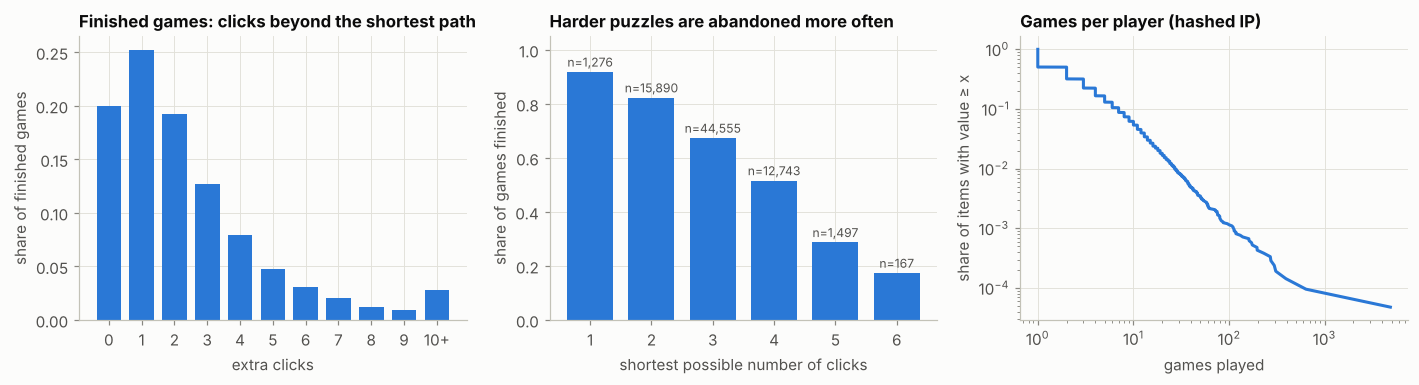

20,868 players; median 2 games, max 4,865; the top 1% of players account for 23% of all games
finished games played optimally: 20.0%


In [9]:
fin = games[games.finished & games.optimal.notna()]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

extra = fin.extra_clicks.clip(upper=10).value_counts(normalize=True).sort_index()
axes[0].bar(extra.index, extra.values, width=0.75, color=viz.BLUE)
axes[0].set_xticks(range(11), [str(i) for i in range(10)] + ["10+"])
axes[0].set(title="Finished games: clicks beyond the shortest path",
            xlabel="extra clicks", ylabel="share of finished games")

success = games.dropna(subset=["optimal"]).query("optimal >= 1 and optimal <= 6")
rate = success.groupby("optimal").finished.agg(["mean", "size"])
axes[1].bar(rate.index, rate["mean"], width=0.75, color=viz.BLUE)
for x, (m, n) in rate.iterrows():
    axes[1].text(x, m + 0.02, f"n={int(n):,}", ha="center", fontsize=8, color=viz.INK_2)
axes[1].set(title="Harder puzzles are abandoned more often", ylim=(0, 1.05),
            xlabel="shortest possible number of clicks", ylabel="share of games finished")

viz.ccdf(axes[2], games.groupby("ip").size().to_numpy(), color=viz.BLUE)
axes[2].set(title="Games per player (hashed IP)", xlabel="games played")
fig.tight_layout()
plt.show()

ipc = games.groupby("ip").size()
top1 = ipc.sort_values(ascending=False).head(len(ipc) // 100).sum() / len(games)
print(f"{len(ipc):,} players; median {ipc.median():.0f} games, max {ipc.max():,}; "
      f"the top 1% of players account for {top1:.0%} of all games")
print(f"finished games played optimally: {(fin.extra_clicks == 0).mean():.1%}")

**Observations.**
* Two thirds of the games are finished (67.4%). The others end with a new game (*restart*, 20.4%) or after 30 minutes of inactivity (*timeout*, 12.2%, hence their median duration of 31 minutes).
* A finished game takes 5 clicks (median) where 3 would suffice, and only 20% of finished games are played optimally (2.5 extra clicks on average).
* Difficulty matters a lot: 92% of the puzzles whose target is one click away are finished, against 52% at four clicks and 17% at six. Every comparison in RQ3 must therefore hold the remaining distance fixed.
* Players are very unequal. There are 20,868 hashed IPs with a median of 2 games each, but one IP played 4,865 games and the top 1% of players account for 23% of all games. We cluster standard errors by player.
* Ratings exist for 56% of the finished games and never for unfinished ones. They are not missing at random, so we use them only descriptively.

### 2.2 The link graph

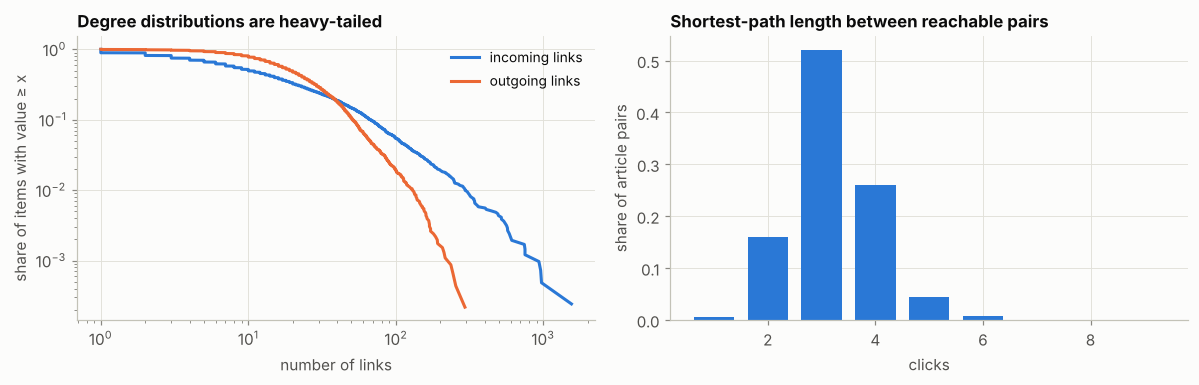

mean out-degree 26.0 (median 19); Spearman(in, out) = 0.60


,title,in_degree,out_degree,topic
article_id,,,,
4297,United States,1551,294,Countries
4293,United Kingdom,972,168,Countries
1568,France,959,85,Countries
1433,Europe,933,159,Geography
1385,England,751,172,Geography
4542,World War II,751,119,History
1694,Germany,743,169,Countries
2098,India,611,81,Geography


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
viz.ccdf(axes[0], articles.in_degree.to_numpy(), label="incoming links", color=viz.BLUE)
viz.ccdf(axes[0], articles.out_degree.to_numpy(), label="outgoing links", color=viz.ORANGE)
axes[0].legend()
axes[0].set(title="Degree distributions are heavy-tailed", xlabel="number of links")

reach = dist[(dist != 255) & ~np.eye(N_ARTICLES, dtype=bool)]
counts = pd.Series(reach).value_counts(normalize=True).sort_index()
axes[1].bar(counts.index, counts.values, width=0.75, color=viz.BLUE)
axes[1].set(title="Shortest-path length between reachable pairs",
            xlabel="clicks", ylabel="share of article pairs")
fig.tight_layout()
plt.show()

print(f"mean out-degree {articles.out_degree.mean():.1f} (median {articles.out_degree.median():.0f}); "
      f"Spearman(in, out) = {articles[['in_degree', 'out_degree']].corr('spearman').iloc[0, 1]:.2f}")
articles.nlargest(8, "in_degree")[["title", "in_degree", "out_degree", "topic"]]

**Observations.** The graph is small but very centralised. In-degrees are far more skewed than out-degrees: *United States* is linked from 1,551 of the 4,604 articles, and the hubs are countries, continents and *World War II*. Most reachable pairs are 3 clicks apart, the longest shortest path is 9 clicks, 12.3% of ordered pairs are not connected, and 474 articles have no incoming link at all. This heavy tail is why popularity enters the model as $\log(1 + \text{in-degree})$. Because in- and out-degree are correlated (0.60), the popularity control also captures part of the "hub" appeal of an article.

### 2.3 Articles: topic, length and tone

Each article belongs to one or more of 129 categories in a three-level hierarchy (`subject.Science.Biology.Mammals`). We split it into levels; an article with two categories counts in both. From the plain text we compute the length and the emotional tone (valence) with the VADER lexicon, ignoring the words of the article's own title (otherwise *Dead Sea* or *Great Britain* would be scored by their names).

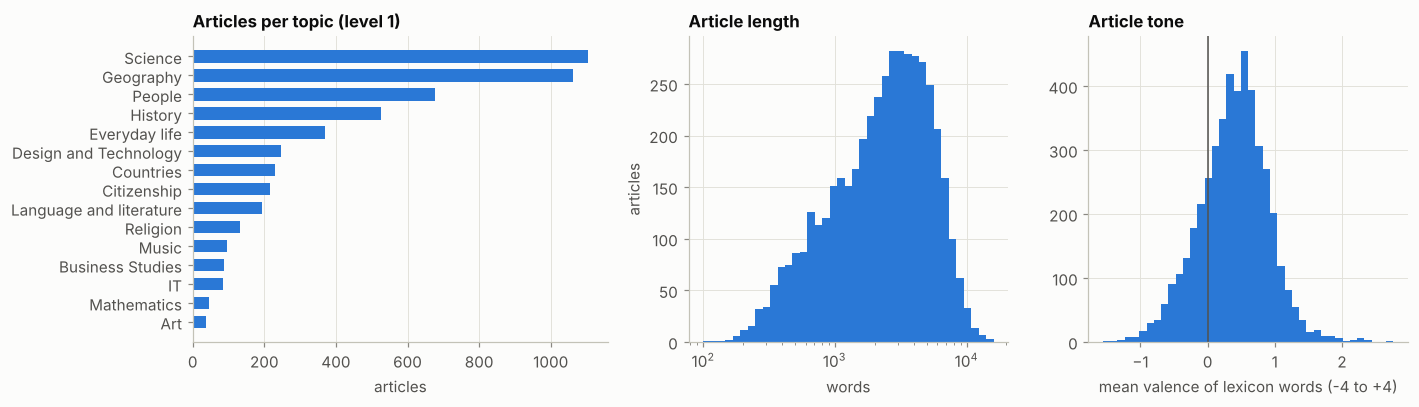

,log_words,valence,neg_share,log_in,log_out
log_words,1.00,-0.16,0.35,0.35,0.58
valence,-0.16,1.00,-0.77,-0.00,-0.07
neg_share,0.35,-0.77,1.00,-0.00,0.09
log_in,0.35,-0.00,-0.00,1.00,0.60
log_out,0.58,-0.07,0.09,0.60,1.00


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
topic_counts = categories.drop_duplicates(["article", "level1"]).level1.value_counts().sort_values()
axes[0].barh(topic_counts.index.str.replace("_", " "), topic_counts.values, height=0.65, color=viz.BLUE)
axes[0].set(title="Articles per topic (level 1)", xlabel="articles")
axes[0].grid(axis="y", visible=False)

axes[1].hist(articles.n_words, bins=np.geomspace(100, 16000, 40), color=viz.BLUE)
axes[1].set_xscale("log")
axes[1].set(title="Article length", xlabel="words", ylabel="articles")

axes[2].hist(articles.valence, bins=40, color=viz.BLUE)
axes[2].axvline(0, color=viz.INK_2, linewidth=1)
axes[2].set(title="Article tone", xlabel="mean valence of lexicon words (-4 to +4)")
fig.tight_layout()
plt.show()

art_vars = articles.assign(log_words=np.log(articles.n_words),
                           log_in=np.log1p(articles.in_degree), log_out=np.log1p(articles.out_degree))
art_vars[["log_words", "valence", "neg_share", "log_in", "log_out"]].corr("spearman").round(2)

In [12]:
tone = articles[articles.n_words >= 300].sort_values("valence")
pd.DataFrame({"most negative": tone.title.head(8).to_numpy(),
              "most positive": tone.title.tail(8).to_numpy()[::-1]})

,most negative,most positive
0,List of Archbishops of Canterbury,List of African countries
1,Mauthausen-Gusen concentration camp,Weasel
2,Terrorism,Saurischia
3,Tropical Storm Bonnie (2004),Thrush (bird)
4,Tropical Storm Allison,HD 217107
5,Tropical Storm Leslie (2000),Grand Slam (tennis)
6,Arthur Upfield,List of European countries
7,July 2006 Java earthquake,Chiltern Hills


**Observations.** Science and geography dominate the topics. Articles are long (median about 2,500 words, from 100 to 15,700), which is good for locating links and measuring tone in the text. Tone is mildly positive on average. The most negative articles are about terrorism, concentration camps, storms and earthquakes, which is the variation RQ2 needs. The lexicon also has known blind spots: neutral words can carry an emotional rating, so lists of archbishops score negative and lists of countries positive. We will check the score on a hand-labelled sample in P3. Length is correlated with the number of outgoing (0.58) and incoming (0.35) links, so RQ2 has to separate length from centrality.

### 2.4 Clicks: how often do players get closer?

For each forward click from page $u$ to $v$ with target $t$, we compare the shortest-path distances $\delta = d(v,t) - d(u,t)$. A click is *optimal* when $\delta = -1$, keeps the player *at the same distance* when $\delta = 0$, and moves *away* when $\delta > 0$.

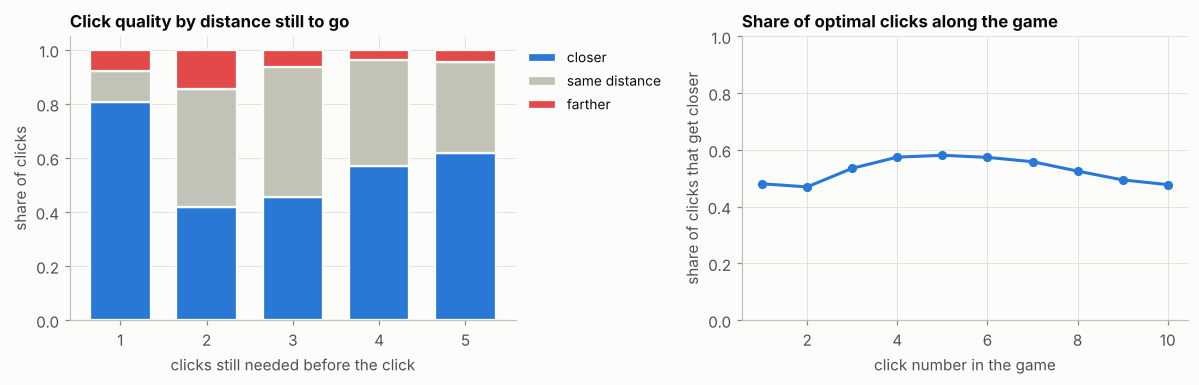

delta,closer,same distance,farther
share,0.515,0.393,0.092


In [13]:
clicks = choices.clicks
overall = desc.click_quality(clicks)
by_distance = desc.click_quality(clicks[clicks.du <= 5], by="du")
by_step = desc.click_quality(clicks[clicks.click_no < 10].assign(click=clicks.click_no + 1), by="click")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
colors = {"closer": viz.AVOIDED, "same distance": viz.NEUTRAL, "farther": viz.TEMPTING}
bottom = np.zeros(len(by_distance))
for col in by_distance.columns:
    axes[0].bar(by_distance.index, by_distance[col], bottom=bottom, width=0.7,
                color=colors[col], label=col, edgecolor=viz.SURFACE, linewidth=1.5)
    bottom += by_distance[col].to_numpy()
axes[0].set(title="Click quality by distance still to go", xlabel="clicks still needed before the click",
            ylabel="share of clicks")
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))
axes[1].plot(by_step.index, by_step["closer"], marker="o", color=viz.BLUE)
axes[1].set(title="Share of optimal clicks along the game", xlabel="click number in the game",
            ylabel="share of clicks that get closer", ylim=(0, 1))
fig.tight_layout()
plt.show()
overall.T

**Observations.**
* Only **51.5%** of the clicks bring players closer to their target. 39.3% leave them at the same distance and 9.2% move them away.
* When the target is on the page (one click away), 81% of the clicks hit it, so about one time in five a player standing next to the target does not see it or does not take it.
* The middle of the game is the hard part: two or three clicks from the target, fewer than half of the clicks are optimal.
* Along the game, the share of optimal clicks rises from 48% to 58% at the fifth click and then falls again, as the games still running are increasingly those that went astray.

### 2.5 Four puzzles played thousands of times

The game proposed a few fixed puzzles to many players. Four source-target pairs were played more than 1,500 times each.

In [14]:
featured = paths.featured_pairs(games)
f_games = games.set_index(["source", "target"]).loc[featured.index].reset_index()
featured_table = f_games.groupby(["source", "target"]).agg(
    games=("game_id", "size"), finished=("finished", "mean"),
    median_clicks=("n_clicks", "median"), shortest=("optimal", "first"))
print(f"{len(f_games):,} games ({len(f_games) / len(games):.1%} of all games) in {len(featured)} puzzles")
featured_table

7,177 games (9.4% of all games) in 4 puzzles


,,games,finished,median_clicks,shortest
source,target,,,,
Asteroid,Viking,1770,0.589,5.0,3.0
Brain,Telephone,2044,0.509,4.0,3.0
Pyramid,Bean,1586,0.405,5.0,3.0
Theatre,Zebra,1777,0.509,5.0,3.0


These puzzles are a gift for RQ3: thousands of players facing the very same decisions. They are a problem for RQ1, however, because a handful of articles on their routes would collect most of their clicks (for example, *Computer science* on the way from *Brain* to *Telephone*). We therefore **estimate temptation without these four puzzles** and keep them for the RQ3 comparisons and the data story.

## 3. From clicks to choices

### 3.1 Choice sets

Click $k$ is made on page $u_k$ with target $t_k$. Its **choice set** $C_k$ is the set of distinct articles linked from $u_k$ (self-links excluded), and the outcome is the clicked article $v_k \in C_k$. Each click thus becomes $|C_k|$ rows, one per candidate link, which is the long format of discrete-choice models.

366,074 choice sets, 23,431,484 candidate rows; links per page: mean 64.0, median 42, max 294


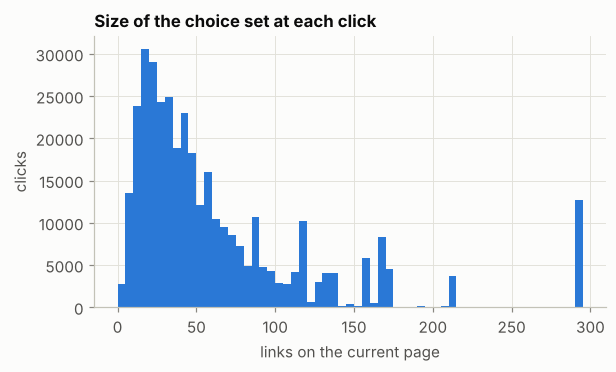

In [15]:
sizes = choices.sizes
print(f"{choices.n_clicks:,} choice sets, {choices.n_rows:,} candidate rows; "
      f"links per page: mean {sizes.mean():.1f}, median {np.median(sizes):.0f}, max {sizes.max()}")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(sizes, bins=np.arange(0, 300, 5), color=viz.BLUE)
ax.set(title="Size of the choice set at each click", xlabel="links on the current page",
       ylabel="clicks")
plt.show()

### 3.2 Features of a candidate link

For candidate $j$ of click $k$ we compute:

| group | feature | definition |
|---|---|---|
| usefulness (objective) | `closer`, `farther` | $d(j,t) = d(u,t) - 1$, or $d(j,t) > d(u,t)$; *same distance* is the reference |
| | `is_target` | $j = t$, the target itself is on the page |
| | `dead_end` | $t$ cannot be reached from $j$ (259 rows, counted as `farther`; not a separate model feature) |
| usefulness (perceived) | `similarity` | TF-IDF cosine similarity between the texts of $j$ and $t$ (z-score) |
| visibility | `position` | offset of the first mention of $j$ in the text of $u$ divided by the text length (0 = top) |
| | `position_missing` | the anchor text of $j$ was not found in $u$ |
| | `log_mentions` | $\log(1 + \text{number of mentions of } j \text{ in } u)$ |
| popularity | `log_indegree` | $\log(1 + \text{number of articles linking to } j)$ (z-score) |
| game state | `visited` | $j$ was already visited earlier in the same game |

**Similarity.** Each article body is a TF-IDF vector with sublinear term frequency, $w_{a,w} = (1 + \log \mathrm{tf}_{a,w}) \cdot \big(1 + \log\frac{1 + N}{1 + \mathrm{df}_w}\big)$, over words appearing in at least 2 and at most 50% of the articles (English stop words removed). Rows are L2-normalised, so the cosine similarity is a dot product and the full 4604 × 4604 matrix (85 MB) is one sparse matrix product. The target's similarity to itself (always 1) is set to the mean so that `is_target` alone captures the pull of the target.

**Position.** The plain text follows the order of the page that players saw (infobox, body, navigation boxes), so the first mention of a link's title approximates its vertical position. Titles are matched loosely (case-insensitive, disambiguation removed, small suffixes allowed, so *Iran* matches *Iranian*).

In [16]:
found = links[links.source_id != links.target_id].found
print(f"anchor found for {found.mean():.1%} of the links")
X, chosen = choices.X, choices.chosen
feature_table = pd.DataFrame({
    "description": pd.Series(FEATURE_DESCRIPTIONS),
    "mean over all candidate links": X.mean(axis=0, dtype=np.float64),
    "mean over clicked links": X[chosen].mean(axis=0, dtype=np.float64),
}).round(3)
found_rows = X[:, choices.feature_names.index("position_missing")] == 0
pos = X[:, choices.feature_names.index("position")]
clicked_found = choices.chosen[found_rows[choices.chosen]]
print(f"mean position among links whose anchor was found: all {pos[found_rows].mean():.2f}, "
      f"clicked {pos[clicked_found].mean():.2f}")
feature_table

anchor found for 86.2% of the links


mean position among links whose anchor was found: all 0.43, clicked 0.24


,description,mean over all candidate links,mean over clicked links
closer,j is one click closer to the target than u (shortest-pat...,0.083,0.515
farther,j is farther from the target than u (including when t ca...,0.473,0.092
is_target,j is the target itself,0.003,0.140
dead_end,"the target cannot be reached from j (descriptive only, p...",0.000,0.000
similarity,TF-IDF cosine similarity between j and the target (z-score),0.000,0.695
position,relative position of the first mention of j on page u (0...,0.367,0.219
position_missing,the link anchor of j was not found in the text of u,0.139,0.091
log_mentions,log(1 + number of mentions of j on page u),1.069,1.496
log_indegree,log(1 + number of articles linking to j) (z-score),0.000,0.203
visited,j was already visited earlier in the same game,0.013,0.022


In [17]:
sample_rows = desc.sample_rows(choices, n=400_000)
sample_rows.drop(columns=["dead_end", "clicked"]).corr("spearman").round(2)

,closer,farther,is_target,similarity,position,position_missing,log_mentions,log_indegree,visited
closer,1.00,-0.29,0.18,0.08,-0.04,-0.02,0.04,0.09,0.01
farther,-0.29,1.00,-0.05,-0.05,0.05,0.03,-0.07,-0.12,-0.01
is_target,0.18,-0.05,1.00,0.02,-0.01,-0.01,0.02,-0.03,-0.01
similarity,0.08,-0.05,0.02,1.00,-0.04,0.00,0.07,0.11,0.04
position,-0.04,0.05,-0.01,-0.04,1.00,-0.60,0.08,-0.06,-0.05
position_missing,-0.02,0.03,-0.01,0.00,-0.60,1.00,-0.62,-0.15,-0.02
log_mentions,0.04,-0.07,0.02,0.07,0.08,-0.62,1.00,0.29,0.08
log_indegree,0.09,-0.12,-0.03,0.11,-0.06,-0.15,0.29,1.00,0.06
visited,0.01,-0.01,-0.01,0.04,-0.05,-0.02,0.08,0.06,1.00


**Observations.** Clicked links differ from the average candidate in every feature. They are six times more often a step closer to the target (52% against 8%) and five times less often a step away (9% against 47%). They are 0.69 standard deviations more similar to the target, sit higher on the page (mean position 0.24 against 0.43 among links whose anchor was found) and are mentioned more often. The features are only weakly correlated with each other, so their effects can be separated. The exception is `position_missing`, which is correlated with both `position` (-0.60) and `log_mentions` (-0.62): a link whose anchor is not found has neither a position nor mentions.

### 3.3 Model-free evidence

Before any model, the click-through rate (clicks / times offered) of candidate links already shows the forces we want to control for.

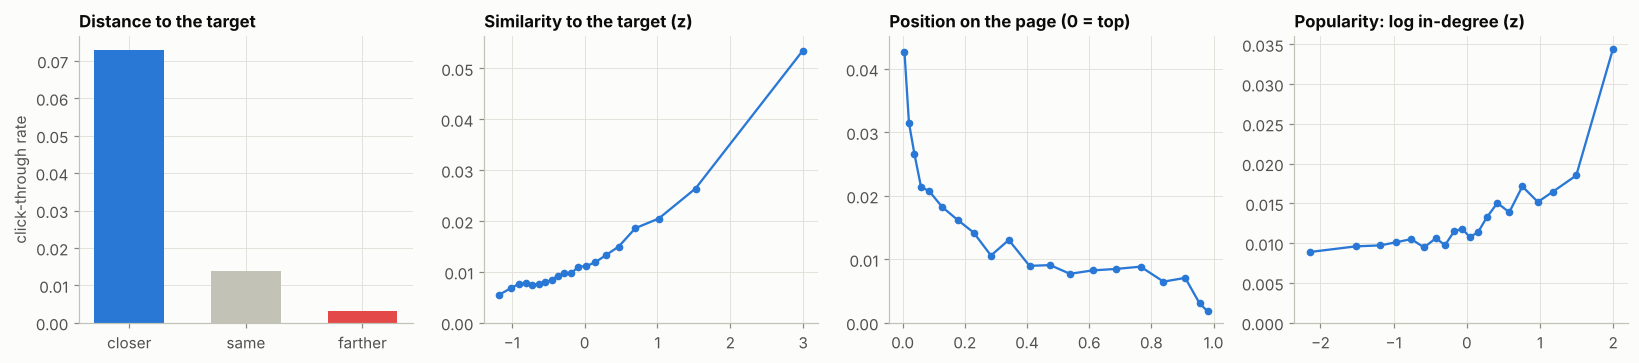

In [18]:
fn = choices.feature_names
col = {name: X[:, i] for i, name in enumerate(fn)}
not_target = col["is_target"] == 0

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=False)
dist_class = np.where(col["closer"] == 1, 0, np.where(col["farther"] == 1, 2, 1)).astype(float)
ctr = desc.click_through(choices, dist_class, bins=np.array([-0.5, 0.5, 1.5, 2.5]), row_mask=not_target)
axes[0].bar(["closer", "same", "farther"], ctr["ctr"], width=0.6,
            color=[viz.AVOIDED, viz.NEUTRAL, viz.TEMPTING])
axes[0].set(title="Distance to the target", ylabel="click-through rate")

panels = [("similarity", "Similarity to the target (z)", not_target),
          ("position", "Position on the page (0 = top)", not_target & (col["position_missing"] == 0)),
          ("log_indegree", "Popularity: log in-degree (z)", not_target)]
for ax, (name, title, mask) in zip(axes[1:], panels):
    c = desc.click_through(choices, col[name], bins=20, row_mask=mask)
    ax.errorbar(c["value"], c["ctr"], yerr=1.96 * c["ctr_se"], color=viz.BLUE, marker="o",
                markersize=4, linewidth=1.5, elinewidth=1)
    ax.set(title=title, ylim=(0, None))
for ax in axes:
    ax.title.set_fontsize(10)
fig.tight_layout()
plt.show()

**Observations.** Every force shows up without any model:
* a link one step closer is clicked 5 times more often than a link at the same distance and more than 20 times more often than a link leading away (7.3% vs 1.4% vs 0.3%);
* click-through grows tenfold from the least to the most similar links;
* links at the very top of the page are clicked 4 to 5 times more often than links in the middle and 20 times more often than the last ones;
* popular articles are clicked more.

These forces are the controls of the choice model. Temptation is what is left once they are accounted for.

## 4. The choice model

### 4.1 Conditional logit

We use McFadden's conditional logit. Candidate $j$ of click $k$ has utility $U_{kj} = \beta^\top x_{kj} + \varepsilon_{kj}$ with independent Gumbel noise, so

$$
P(y_k = j \mid C_k) = \frac{\exp(\beta^\top x_{kj})}{\sum_{l \in C_k} \exp(\beta^\top x_{kl})}.
$$

Only differences between links of the same page matter: anything constant within a page (the player, the target, the page itself) cancels out. The log-likelihood

$$
\ell(\beta) = \sum_k \Big[\beta^\top x_{k y_k} - \log \sum_{l \in C_k} e^{\beta^\top x_{kl}}\Big]
$$

is concave, with gradient $\nabla \ell = \sum_k (x_{k y_k} - \bar x_k)$ where $\bar x_k = \sum_l p_{kl} x_{kl}$, and Fisher information $I(\beta) = \sum_k \sum_l p_{kl}(x_{kl} - \bar x_k)(x_{kl} - \bar x_k)^\top$. We maximise it with a damped Newton method (`src/models/conditional_logit.py`), streaming over the 23M rows in chunks; it converges in fewer than ten iterations. Clicks of the same player are not independent (one hashed IP played 4,865 games), so we report **cluster-robust standard errors** $I^{-1} M I^{-1}$ with $M = \frac{G}{G-1}\sum_g s_g s_g^\top$, where $s_g$ sums the per-click scores $x_{k y_k} - \bar x_k$ of player $g$.

We wrote our own estimator because the 23.4M × 9 design does not fit the dense, in-memory implementations (statsmodels needs float64 copies and its default optimiser stops early). `tests/test_conditional_logit.py` checks that it recovers simulated coefficients and matches statsmodels' `ConditionalLogit` (Newton) to $10^{-6}$ on a small problem.

### 4.2 Fit on the scoring sample

The scoring sample is every modelable click outside the four featured puzzles.

In [19]:
featured_games = games.set_index(["source", "target"]).index.isin(featured.index)
featured_ids = games.loc[featured_games, "game_id"]
is_featured_click = clicks.game_id.isin(featured_ids).to_numpy()
sample = choices.subset(~is_featured_click)
print(f"scoring sample: {sample.n_clicks:,} clicks, {sample.n_rows:,} rows "
      f"({is_featured_click.sum():,} clicks of featured puzzles set aside)")

FEATURES = ["closer", "farther", "is_target", "similarity", "position", "position_missing",
            "log_mentions", "log_indegree", "visited"]
t0 = time.time()
model = ConditionalLogit(FEATURES).fit(sample, cluster="ip")
print(f"fitted in {time.time() - t0:.0f} s, {model.n_iter_} Newton iterations, "
      f"{model.n_clusters_:,} player clusters, McFadden pseudo-R2 = {model.pseudo_r2_:.3f}")
coef = model.summary()
coef

scoring sample: 331,648 clicks, 21,508,162 rows (34,426 clicks of featured puzzles set aside)


fitted in 29 s, 6 Newton iterations, 17,813 player clusters, McFadden pseudo-R2 = 0.314


,coef,odds_ratio,se,se_robust,z,p_value
feature,,,,,,
closer,1.013,2.753,0.005,0.024,41.663,0.000e+00
farther,-0.804,0.447,0.008,0.028,-28.582,1.123e-179
is_target,5.759,317.052,0.017,0.049,117.922,0.000e+00
similarity,0.841,2.320,0.002,0.006,131.273,0.000e+00
position,-1.379,0.252,0.009,0.021,-65.217,0.000e+00
position_missing,-0.354,0.702,0.009,0.013,-27.148,2.707e-162
log_mentions,0.312,1.366,0.003,0.004,80.970,0.000e+00
log_indegree,0.109,1.115,0.002,0.005,23.735,1.558e-124
visited,-0.453,0.636,0.013,0.030,-15.263,1.354e-52


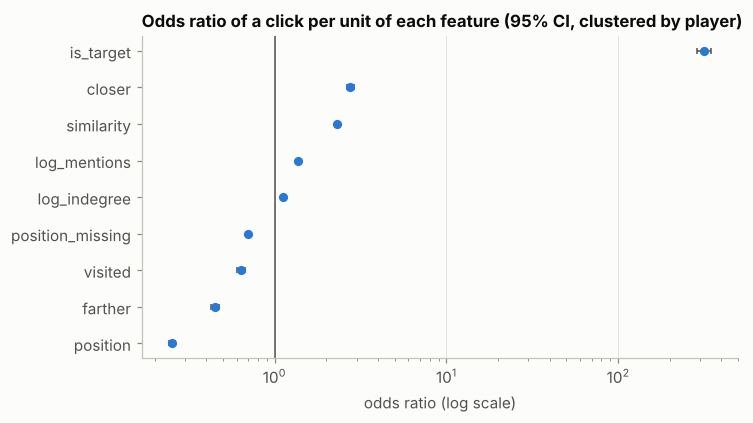

In [20]:
fig, ax = plt.subplots(figsize=(7, 3.8))
order = coef.sort_values("coef").index
ci_low = np.exp(coef.loc[order, "coef"] - 1.96 * coef.loc[order, "se_robust"])
ci_high = np.exp(coef.loc[order, "coef"] + 1.96 * coef.loc[order, "se_robust"])
odds = coef.loc[order, "odds_ratio"]
ax.errorbar(odds, range(len(order)), xerr=[odds - ci_low, ci_high - odds], fmt="o",
            color=viz.BLUE, ecolor=viz.INK_2, elinewidth=1, capsize=2)
ax.axvline(1, color=viz.INK_2, linewidth=1)
ax.set_xscale("log")
ax.set_yticks(range(len(order)), order)
ax.grid(axis="y", visible=False)
ax.set(title="Odds ratio of a click per unit of each feature (95% CI, clustered by player)",
       xlabel="odds ratio (log scale)")
plt.show()

**Observations.** All coefficients are large and precisely estimated. The robust standard errors are 1.3 to 5 times the classical ones, as expected when some players play hundreds of games.
* A link one step **closer** has 2.8 times the odds of a link at the same distance, and a link leading **away** 0.45 times. The **target** itself, when present, is almost irresistible: its odds are about 870 times those of a link at the same distance (× 317 on top of being one step closer).
* One standard deviation of **similarity** to the target multiplies the odds by 2.3, about as much as being a step closer. Players cannot see the graph distance, yet their clicks track it beyond what text similarity explains.
* **Visibility** matters: a link at the bottom of the page has a quarter of the odds of one at the top, and each doubling of (1 + number of mentions) multiplies the odds by 1.24 ($2^{0.312}$).
* **Popular** articles are slightly favoured (× 1.12 per standard deviation of log in-degree), and players rarely go back through a link to a page they already visited (× 0.64).

### 4.3 Does the model predict held-out clicks?

We split the scoring sample by game (80% train, 20% test) and compare nested specifications on the test games: the average log-likelihood per click, McFadden's pseudo-$R^2$ against random clicking, the share of clicks where the clicked link is the model's top choice, and the mean share of links ranked above the clicked one.

In [21]:
specs = {
    "popularity only": ["log_indegree"],
    "+ visibility": ["log_indegree", "position", "position_missing", "log_mentions"],
    "+ distance to target": ["log_indegree", "position", "position_missing", "log_mentions",
                             "closer", "farther", "is_target"],
    "+ similarity to target": ["log_indegree", "position", "position_missing", "log_mentions",
                               "closer", "farther", "is_target", "similarity"],
    "full (+ visited)": FEATURES,
}
t0 = time.time()
heldout = compare_specifications(sample, specs, test_share=0.2, seed=0)
print(f"{heldout.attrs['n_train']:,} training / {heldout.attrs['n_test']:,} test clicks, "
      f"{time.time() - t0:.0f} s")
heldout

265,273 training / 66,375 test clicks, 74 s


,n_params,loglik_per_click,pseudo_r2,top1_accuracy,mean_rank_pct
model,,,,,
random click,0,-3.771,0.000,0.036,0.482
popularity only,1,-3.754,0.005,0.078,0.425
+ visibility,4,-3.612,0.042,0.091,0.335
+ distance to target,7,-2.812,0.254,0.311,0.199
+ similarity to target,8,-2.588,0.314,0.353,0.161
full (+ visited),9,-2.586,0.314,0.354,0.161


**Observations.** On 66k clicks from games never seen during fitting, the full model ranks the clicked link first 35% of the time (random clicking: 3.6%) and above 84% of the page's other links on average, with a pseudo-$R^2$ of 0.31. Distance to the target brings the largest gain and similarity the second, so the model captures goal-directed navigation. In-sample and out-of-sample fit are the same (pseudo-$R^2$ 0.314 on both), so 9 parameters on 265k clicks do not overfit. The `visited` indicator adds almost nothing, and we may drop it in P3.

## 5. Temptation (RQ1)

### 5.1 Observed versus expected clicks

For each article $a$ we compare the clicks it received, $O_a$, with the clicks the model expects, $E_a = \sum_{k:\, a \in C_k} \hat p_{ka}$: the predicted probability summed over every page view on which a link to $a$ was offered. The ratio $O_a / E_a$ is the article's **temptation**. Above 1, players pick the article more often than its usefulness, visibility and popularity explain; below 1, they avoid it. Rows where the article *is* the target are left out: the pull of the target is captured by `is_target` and says nothing about the article's own appeal.

The ratio is the natural one-step approximation of an article fixed effect $\gamma_a$ added to the utility. The score at $\gamma_a = 0$ is $\partial \ell / \partial \gamma_a = O_a - E_a$, and with $\beta$ held fixed and small choice probabilities the maximum-likelihood estimate is $\hat\gamma_a \approx \log(O_a / E_a)$. At the maximum-likelihood estimate of $\beta$ the residuals are orthogonal to the features ($\sum_k (x_{k y_k} - \bar x_k) = 0$), so temptation is, by construction, what the features cannot explain.

Rarely offered articles have noisy ratios, so we shrink them with a **Gamma-Poisson empirical-Bayes model**:

$$
O_a \mid \theta_a \sim \mathrm{Poisson}(\theta_a E_a), \qquad \theta_a \sim \mathrm{Gamma}(\alpha, \beta) \;\Rightarrow\; \theta_a \mid O_a \sim \mathrm{Gamma}(\alpha + O_a,\ \beta + E_a).
$$

The marginal of $O_a$ is negative binomial and we fit $(\alpha, \beta)$ by maximising it. The prior mean $\alpha/\beta$ is left free: only the click-weighted average of the ratios is 1, not that of the typical article. The posterior mean $(\alpha + O_a)/(\beta + E_a)$ pulls weakly measured articles towards the prior mean and leaves well-measured ones at their raw ratio.

**Overdispersion.** An article's pull varies from one target to another, so its clicks vary more than Poisson: $\mathrm{Var}(O_a \mid \theta_a) = \phi\, \theta_a E_a$. We estimate $\phi$ with a bootstrap over targets (resampling targets, recomputing $O_a$ and $E_a$, and comparing the variance of $\log(O_a/E_a)$ with its Poisson value $1/O_a$ for articles with at least 30 clicks). We then fit the model on the quasi-Poisson counts $O_a/\phi$ and $E_a/\phi$, which widens the intervals by about $\sqrt{\phi}$.

three scores with bootstrap dispersion estimates in 58 s


,candidate rows,dispersion phi,prior mean,prior shape alpha,articles offered,articles with E >= 10
overall,2.145e+07,1.71,1.09,2.15,4078.0,2358.0
siren,1.975e+07,1.59,1.16,1.74,4077.0,2027.0
monster,1.697e+06,1.60,0.97,3.60,3854.0,1446.0


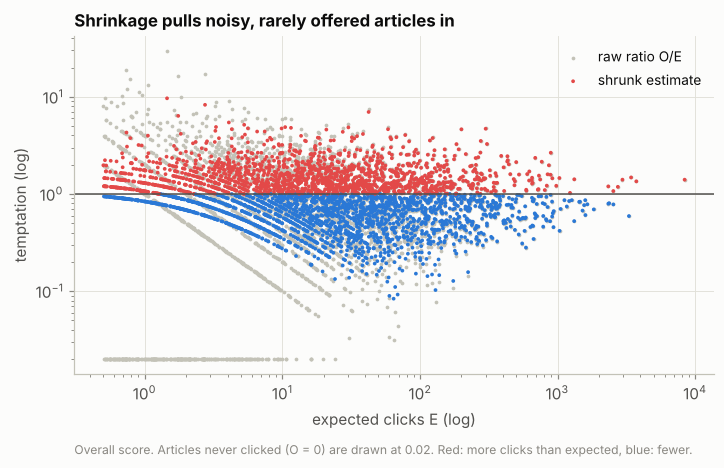

In [22]:
proba = model.predict_proba(sample)
fn = sample.feature_names
closer = sample.X[:, fn.index("closer")] == 1
is_target = sample.X[:, fn.index("is_target")] == 1
strata = {"overall": ~is_target, "siren": ~closer & ~is_target, "monster": closer & ~is_target}

t0 = time.time()
scored = {name: temptation.score(sample, proba, N_ARTICLES, mask) for name, mask in strata.items()}
print(f"three scores with bootstrap dispersion estimates in {time.time() - t0:.0f} s")
display(pd.DataFrame({
    name: {"candidate rows": int(strata[name].sum()), "dispersion phi": s.attrs["phi"],
           "prior mean": s.attrs["prior"][0] / s.attrs["prior"][1], "prior shape alpha": s.attrs["prior"][0],
           "articles offered": int((s.exposure > 0).sum()), "articles with E >= 10": int((s.expected >= 10).sum())}
    for name, s in scored.items()}).T.round(2))

info = articles[["title", "topic", "n_words", "valence", "disease"]]
overall, siren, monster = (scored[name].join(info) for name in strata)

offered = overall[overall.expected > 0.5]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(offered.expected, offered.raw_ratio.clip(lower=0.02), s=6, color=viz.NEUTRAL,
           label="raw ratio O/E")
ax.scatter(offered.expected, offered.temptation, s=6,
           c=viz.diverging_colors(offered.log_temptation), label="shrunk estimate")
ax.axhline(1, color=viz.INK_2, linewidth=1)
ax.set(xscale="log", yscale="log", xlabel="expected clicks E (log)",
       ylabel="temptation (log)", title="Shrinkage pulls noisy, rarely offered articles in")
ax.legend(loc="upper right")
viz.note(ax, "Overall score. Articles never clicked (O = 0) are drawn at 0.02. Red: more clicks than expected, blue: fewer.")
plt.show()

### 5.2 Sirens and monsters

Following the proposal, a **siren** is clicked *even when the click is costly* and a **monster** is avoided *even when it is the best move*. The two scores computed above use exactly these two strata of candidate rows: the rows where the link does **not** bring the player closer (siren score), and the rows where it is an **optimal** move (monster score; low is monstrous).

In [23]:
show = ["title", "topic", "observed", "expected", "temptation", "ci_low", "ci_high"]
top_sirens = siren[siren.expected >= 10].nlargest(15, "temptation")[show]
top_monsters = monster[monster.expected >= 10].nsmallest(15, "temptation")[show]
print("Sirens: clicked far more often than expected when the click does not help")
display(top_sirens)
print("Monsters: avoided when they are the best move")
display(top_monsters)

Sirens: clicked far more often than expected when the click does not help


,title,topic,observed,expected,temptation,ci_low,ci_high
article_id,,,,,,,
1640,Gardening,Everyday_life,106.0,11.765,7.690,6.229,9.279
919,Cinema of the United States,Everyday_life,182.0,24.686,6.827,5.821,7.899
1598,Fresh water,Geography,119.0,18.601,5.804,4.759,6.935
871,Chemical element,Science,753.0,136.663,5.436,5.033,5.851
3315,Popular culture,Citizenship,216.0,38.935,5.295,4.576,6.058
1246,Drinking water,Everyday_life,69.0,11.566,5.147,3.956,6.466
592,Bird of prey,Science,77.0,14.281,4.788,3.734,5.950
2897,Musical instrument,Music,133.0,27.063,4.611,3.823,5.460
1922,Herbivore,Science,211.0,44.481,4.562,3.935,5.227


Monsters: avoided when they are the best move


,title,topic,observed,expected,temptation,ci_low,ci_high
article_id,,,,,,,
340,Armenia,Countries,6.0,67.800,0.160,0.077,0.267
725,Bulgaria,Countries,7.0,72.566,0.163,0.081,0.268
3450,Redshift,Science,1.0,34.717,0.166,0.059,0.318
4009,Technetium,Science,1.0,29.308,0.192,0.068,0.367
3072,OpenOffice.org,IT,10.0,62.787,0.229,0.124,0.361
593,Birmingham,Geography,6.0,45.280,0.230,0.110,0.385
2424,Law,Citizenship,73.0,310.952,0.249,0.193,0.310
581,Binomial nomenclature,Science,7.0,45.146,0.250,0.124,0.411
425,BASIC,IT,1.0,20.816,0.253,0.090,0.483


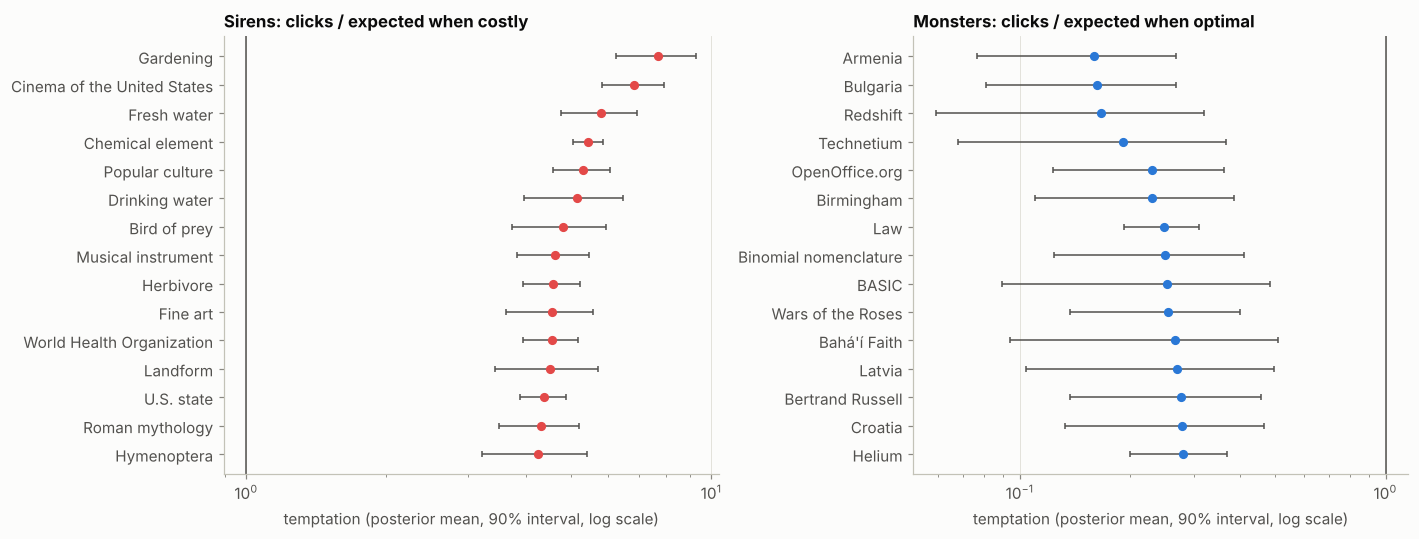

Spearman correlation of the siren and monster scores over 1,369 articles: 0.73


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, table, color, title in [
        (axes[0], top_sirens.iloc[::-1], viz.TEMPTING, "Sirens: clicks / expected when costly"),
        (axes[1], top_monsters.iloc[::-1], viz.AVOIDED, "Monsters: clicks / expected when optimal")]:
    y = np.arange(len(table))
    ax.errorbar(table.temptation, y, xerr=[table.temptation - table.ci_low, table.ci_high - table.temptation],
                fmt="o", color=color, ecolor=viz.INK_2, elinewidth=1, capsize=2)
    ax.axvline(1, color=viz.INK_2, linewidth=1)
    ax.set_xscale("log")
    ax.set_yticks(y, table.title)
    ax.grid(axis="y", visible=False)
    ax.set(title=title, xlabel="temptation (posterior mean, 90% interval, log scale)")
fig.tight_layout()
plt.show()

both = siren.join(monster, rsuffix="_m").query("expected >= 10 and expected_m >= 10")
print(f"Spearman correlation of the siren and monster scores over {len(both):,} articles: "
      f"{both[['log_temptation', 'log_temptation_m']].corr('spearman').iloc[0, 1]:.2f}")

**First sirens and monsters.** Clear patterns appear. They are hypotheses for P3, not conclusions yet:
* **Sirens are broad concept articles**: *Gardening*, *Fresh water*, *Drinking water*, *Landform*, *Fine art*, *Musical instrument*, *Popular culture*, *Chemical element*. When stuck, players seem to climb to a general article that feels like a crossroads, even when the graph says it is a detour. This resembles the "reach a hub, then home in" strategy described by West & Leskovec (2012), but these articles stand out *after* controlling for popularity.
* **Monsters are specific instances**: small countries (*Armenia*, *Bulgaria*, *Latvia*, *Croatia*), chemical elements (*Technetium*, *Helium*), specific places, people and events (*Birmingham*, *Bertrand Russell*, *Wars of the Roses*). Players do not take them even when they are the shortest way. Part of this may come from how the links are shown: such articles often sit in long lists and navigation boxes, which our text-based position cannot see. Exact positions from the HTML release are our first P3 task.
* The two scores are strongly correlated (Spearman 0.73). Articles that lure players when useless are also taken more when useful, so temptation behaves largely like a single trait of the article.
* The counts are overdispersed ($\phi \approx 1.6$ to $1.7$), and the intervals account for it. The intervals of the rarely clicked monsters still span a factor of up to 5, which is why every ranking keeps them.

### 5.3 Are the scores reliable?

A score is only worth explaining if it is stable. We split the data in two halves, estimate the score on each and correlate the two estimates across articles (at least 5 expected clicks in each half). Splitting by **game** measures sampling noise, splitting by **player** checks that a few heavy players do not drive the scores, and splitting by **target** is the hardest test: the two halves contain different puzzles, so agreement means that temptation belongs to the article and not to a few puzzles. The Spearman-Brown formula $2r/(1+r)$ converts the half-data correlation into the reliability of the full-data score.

16 s


articles  half-data Spearman  reliability
score   split by                                           
overall games       2290.4               0.886        0.939
        players     2272.8               0.883        0.938
        targets     2204.4               0.824        0.904
siren   games       1974.4               0.880        0.936
        players     1947.6               0.877        0.935
        targets     1900.6               0.827        0.905
monster games       1344.2               0.820        0.901
        players     1330.0               0.806        0.892
        targets     1205.0               0.699        0.822

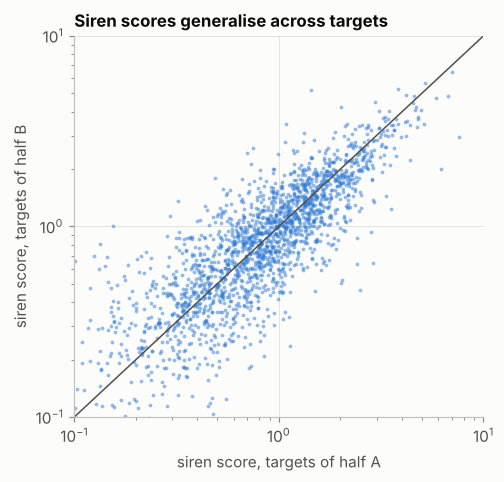

In [25]:
t0 = time.time()
rows = []
for name, mask in strata.items():
    for unit, label in [("game_id", "games"), ("ip", "players"), ("t", "targets")]:
        r = temptation.split_half_reliability(sample, proba, N_ARTICLES, unit=unit, row_mask=mask, n_repeats=5)
        rows.append({"score": name, "split by": label, "articles": r.n_articles.mean(),
                     "half-data Spearman": r.spearman_half.mean(), "reliability": r.spearman_brown.mean()})
reliability = pd.DataFrame(rows).set_index(["score", "split by"])
print(f"{time.time() - t0:.0f} s")
display(reliability.round(3))

by_target = temptation.unit_article_counts(sample, proba, N_ARTICLES, "t", strata["siren"])
halves = temptation.split_half(*by_target, seed=0)
halves = halves[(halves.expected_a >= 5) & (halves.expected_b >= 5)]
fig, ax = plt.subplots(figsize=(4.8, 4.5))
ax.scatter(halves.temptation_a, halves.temptation_b, s=6, alpha=0.5, color=viz.BLUE)
lims = [0.1, 10]
ax.plot(lims, lims, color=viz.INK_2, linewidth=1)
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, xlabel="siren score, targets of half A",
       ylabel="siren score, targets of half B", title="Siren scores generalise across targets")
plt.show()

**Observations.** All three scores are stable. Across random halves of the games or of the players the reliability is 0.89 to 0.94, so neither sampling noise nor a few heavy players drive them. Across halves with **disjoint targets** it is 0.90 for the overall and siren scores and 0.82 for the monster score: temptation belongs to the article, not to a few puzzles. The monster score is the least reliable because optimal moves are rare (1.7M candidate rows against 19.8M for the siren score). This stability is what makes RQ2 meaningful.

## 6. First look at RQ2 and RQ3

### 6.1 RQ2: what makes a siren?

We now relate the **siren score** (and, for the "avoid" side of the question, the monster score) to the article's topic, length and tone. Articles in several categories count in each of them. The proposal's hypotheses become groups of articles: *war and military history*, *animals*, *celebrities* (actors, performers, sports people), *films, TV and games*, *countries* and *chemical elements* come from the categories. *Diseases* are the 54 articles with a medical classification infobox (ICD or DiseasesDB codes): the *Health and medicine* category is too broad, as it also contains *Humour*, *Edible salt* or *Intelligence*.

The model is the count model behind the score itself, a **negative binomial regression** with the expected clicks as exposure (`src/models/explain.py`):

$$
O_a \sim \mathrm{NegBin}\big(\mu_a = E_a\, e^{z_a^\top \gamma},\ \mathrm{Var} = \mu_a + \kappa \mu_a^2\big).
$$

This is the Gamma-Poisson model of section 5.1 with a prior mean that depends on the article's characteristics $z_a$, and $e^{\gamma_j}$ is the multiplier on clicks associated with characteristic $j$. Working with the counts avoids regressing already-shrunk scores, which would attenuate the coefficients. Standard errors are heteroskedasticity-robust.

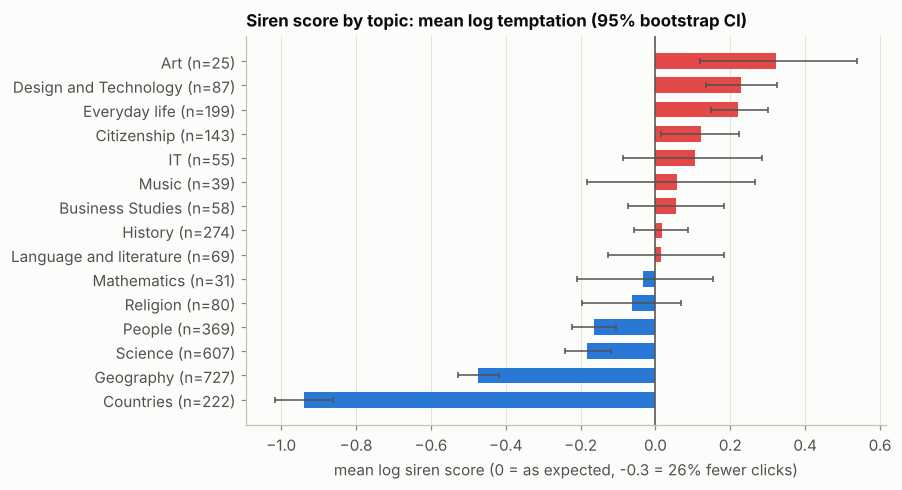

In [26]:
cat_ids = categories.merge(articles[["article"]].reset_index(), on="article")
well_measured = siren[siren.expected >= 5]
by_topic = (cat_ids.drop_duplicates(["article_id", "level1"])
            .merge(well_measured[["log_temptation"]], left_on="article_id", right_index=True))
level1 = desc.group_mean_ci(by_topic, "level1", "log_temptation")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
y = np.arange(len(level1))
ax.barh(y, level1["mean"], height=0.65, color=viz.diverging_colors(level1["mean"]))
ax.errorbar(level1["mean"], y, xerr=[level1["mean"] - level1.ci_low, level1.ci_high - level1["mean"]],
            fmt="none", ecolor=viz.INK_2, elinewidth=1, capsize=2)
ax.set_yticks(y, [f"{t.replace('_', ' ')} (n={n})" for t, n in zip(level1.index, level1.n)])
ax.axvline(0, color=viz.INK_2, linewidth=1)
ax.grid(axis="y", visible=False)
ax.set(title="Siren score by topic: mean log temptation (95% bootstrap CI)",
       xlabel="mean log siren score (0 = as expected, -0.3 = 26% fewer clicks)")
plt.show()

In [27]:
# The proposal's hypotheses as groups of articles (an article can be in several groups)
category_groups = {
    "war_military": "Military_History_and_War|World_War_II|Pre_1900_Military|Conflict_and_Peace",
    "animals": "Mammals|Birds|Insects_Reptiles_and_Fish|Dinosaurs",
    "celebrities": "Actors_models_and_celebrities|Performers_and_composers|Sports_and_games_people",
    "films_tv_games": "Films|Television|Computer_and_Video_games|Cartoons",
    "countries": r"^subject\.Countries|_Countries$",
    "chemical_elements": "Chemical_elements",
}
members = {name: set(cat_ids.loc[cat_ids.category.str.contains(pattern, regex=True), "article_id"])
           for name, pattern in category_groups.items()}
members["diseases"] = set(articles.index[articles.disease])

rows = []
for name, ids in members.items():
    s_ids, m_ids = sorted(ids & set(siren.index[siren.expected >= 5])), sorted(ids & set(monster.index[monster.expected >= 5]))
    rows.append({"group": name, "articles": len(ids),
                 "siren score (geometric mean)": np.exp(siren.loc[s_ids, "log_temptation"].mean()),
                 "monster score (geometric mean)": np.exp(monster.loc[m_ids, "log_temptation"].mean())})
pd.DataFrame(rows).set_index("group").round(2)

,articles,siren score (geometric mean),monster score (geometric mean)
group,,,
war_military,137,0.78,0.85
animals,406,0.97,0.97
celebrities,129,0.77,0.80
films_tv_games,120,1.45,1.20
countries,234,0.39,0.65
chemical_elements,119,0.35,0.55
diseases,54,1.15,0.95


In [28]:
def with_covariates(table):
    return table.assign(log2_words=np.log2(table.n_words),
                        **{name: table.index.isin(ids).astype(int) for name, ids in members.items()})

rhs = "log2_words + valence + " + " + ".join(members)
rq2 = {name: explain.nb_regression(with_covariates(table), rhs) for name, table in [("siren", siren), ("monster", monster)]}
for name, res in rq2.items():
    print(f"{name} score: n = {int(res.nobs):,} articles with E >= 1, NB dispersion kappa = {res.params['alpha']:.2f}")
rq2_table = pd.concat({name: explain.tidy(res)[["multiplier on clicks", "multiplier on clicks (95% CI)", "p_value"]]
                       for name, res in rq2.items()}, axis=1).drop(index="Intercept")
rq2_table.round(3)

siren score: n = 3,426 articles with E >= 1, NB dispersion kappa = 0.50
monster score: n = 2,823 articles with E >= 1, NB dispersion kappa = 0.29


siren                                        \
                  multiplier on clicks multiplier on clicks (95% CI) p_value   
log2_words                       0.868                  0.84 to 0.89   0.000   
valence                          1.056                  0.99 to 1.13   0.118   
war_military                     0.984                  0.81 to 1.19   0.868   
animals                          0.895                  0.80 to 1.00   0.045   
celebrities                      0.943                  0.79 to 1.12   0.496   
films_tv_games                   1.716                  1.39 to 2.12   0.000   
countries                        0.384                  0.35 to 0.42   0.000   
chemical_elements                0.247                  0.21 to 0.29   0.000   
diseases                         1.218                  1.00 to 1.49   0.051   

                               monster                                        
                  multiplier on clicks multiplier on clicks (95% CI) p_value  
log2_words                       0.881                  0.86 to 0.90   0.000  
valence                          1.000                  0.93 to 1.07   0.997  
war_military                     1.019                  0.84 to 1.23   0.843  
animals                          0.945                  0.85 to 1.05   0.279  
celebrities                      0.871                  0.73 to 1.04   0.122  
films_tv_games                   1.413                  1.16 to 1.72   0.001  
countries                        0.647                  0.60 to 0.70   0.000  
chemical_elements                0.429                  0.37 to 0.50   0.000  
diseases                         1.008                  0.87 to 1.16   0.917

**First answers to the proposal's questions.**
* **Countries** and **chemical elements** are rarely chosen, whether the click is costly (siren score × 0.38 and × 0.25) or optimal (monster score × 0.65 and × 0.43). **Films, TV and games** pull players in both situations (× 1.72 and × 1.41).
* **Wars** look avoided in the raw means (siren score × 0.78), but not once length and tone are controlled for (× 0.98): war articles are long. The same holds for **celebrities** (× 0.77 raw, × 0.94 with controls, not significant).
* **Diseases** are not avoided: as the best move they are taken exactly as expected (× 1.01), and as a detour they are, if anything, slightly tempting (× 1.22, p = 0.05). **Animals** are slightly *less* tempting than expected as detours (× 0.90).
* **Length** is the strongest continuous predictor: each doubling of the length goes with 13% fewer clicks than expected as a detour and 12% fewer as the best move. **Tone** has no detectable effect.

So the proposal's guess, "avoid wars and diseases, chase animals and celebrities", is not supported. The dividing line looks rather like **general and entertaining topics versus specific instances and long articles**. In P3 we will test it with all categories, interactions with the target's topic (is a topic avoided in general, or only when it is unrelated to the target?) and a topic model.

### 6.2 RQ3: what does giving in to a siren cost?

Comparing siren clicks with all other clicks would compare different pages, targets and players. We compare clicks made in the **same decision context**: the same page $u$, the same target $t$ and the same distance change $\delta$. Within a context, the siren click and the control click leave the player exactly as far from the target, so the comparison isolates what the article itself does to the rest of the game. With $n^T_c$ siren clicks in context $c$, the effect on the treated is

$$
\hat\tau = \frac{\sum_c n^T_c\, (\bar y^T_c - \bar y^C_c)}{\sum_c n^T_c},
$$

with a bootstrap over contexts for the confidence interval. The outcomes are **giving up** (the game is not finished) and, for finished games, the **extra moves** after the decision: the moves still made (clicks and back clicks) minus the shortest distance still to go. Sirens are the top 10% of the siren score among articles with at least 10 expected clicks. As a benchmark we compare any costly click ($\delta \ge 0$) with an optimal click ($\delta = -1$) on the same page and for the same target, on pages at least two clicks from the target (otherwise the optimal click would simply be the winning click). The siren list was estimated without the four featured puzzles; we report the effects with them, on them alone, and without them.

In [29]:
eligible = siren[siren.expected >= 10]
siren_ids = set(eligible.index[eligible.temptation >= eligible.temptation.quantile(0.9)])
outcomes = cost.click_outcomes(clicks, games)
outcomes["siren"] = outcomes.v.isin(siren_ids)
outcomes["costly"] = outcomes.delta >= 0
outcomes["featured"] = is_featured_click
print(f"{len(siren_ids)} sirens; {outcomes.costly.sum():,} costly clicks, "
      f"{(outcomes.costly & outcomes.siren).sum():,} of them on a siren")

results = {}
for games_label, part in [("all games", outcomes), ("featured puzzles", outcomes[outcomes.featured]),
                          ("other games", outcomes[~outcomes.featured])]:
    for comparison, df, treated, context in [
            ("costly vs optimal", part[part.du >= 2], "costly", ("u", "t")),
            ("siren vs other costly", part[part.costly], "siren", ("u", "t", "delta"))]:
        for outcome in ["gave_up", "extra_after"]:
            results[(comparison, outcome, games_label)] = cost.within_context_effect(df, treated, outcome, context=context)
rq3 = pd.DataFrame(results).T[["n_contexts", "n_treated", "treated_mean", "control_mean", "estimate", "ci_low", "ci_high"]]
rq3.astype({"n_contexts": int, "n_treated": int}).round(3)

203 sirens; 177,519 costly clicks, 35,060 of them on a siren


n_contexts  n_treated  \
costly vs optimal     gave_up     all games              17789      56700   
                      extra_after all games              13500      34899   
siren vs other costly gave_up     all games               6093      13935   
                      extra_after all games               3760       7926   
costly vs optimal     gave_up     featured puzzles         652      16465   
                      extra_after featured puzzles         489       8837   
siren vs other costly gave_up     featured puzzles         371       3639   
                      extra_after featured puzzles         222       2155   
costly vs optimal     gave_up     other games            17157      40038   
                      extra_after other games            13025      25940   
siren vs other costly gave_up     other games             5729      10255   
                      extra_after other games             3543       5743   

                                                    treated_mean  \
costly vs optimal     gave_up     all games                0.363   
                      extra_after all games                3.365   
siren vs other costly gave_up     all games                0.369   
                      extra_after all games                3.331   
costly vs optimal     gave_up     featured puzzles         0.457   
                      extra_after featured puzzles         2.741   
siren vs other costly gave_up     featured puzzles         0.381   
                      extra_after featured puzzles         2.301   
costly vs optimal     gave_up     other games              0.324   
                      extra_after other games              3.574   
siren vs other costly gave_up     other games              0.365   
                      extra_after other games              3.723   

                                                    control_mean  estimate  \
costly vs optimal     gave_up     all games                0.210     0.152   
                      extra_after all games                1.975     1.390   
siren vs other costly gave_up     all games                0.410    -0.042   
                      extra_after all games                4.025    -0.694   
costly vs optimal     gave_up     featured puzzles         0.262     0.195   
                      extra_after featured puzzles         1.571     1.170   
siren vs other costly gave_up     featured puzzles         0.504    -0.122   
                      extra_after featured puzzles         3.082    -0.781   
costly vs optimal     gave_up     other games              0.189     0.134   
                      extra_after other games              2.112     1.462   
siren vs other costly gave_up     other games              0.378    -0.013   
                      extra_after other games              4.379    -0.656   

                                                    ci_low  ci_high  
costly vs optimal     gave_up     all games          0.138    0.169  
                      extra_after all games          1.218    1.541  
siren vs other costly gave_up     all games         -0.061   -0.025  
                      extra_after all games         -1.190   -0.309  
costly vs optimal     gave_up     featured puzzles   0.148    0.257  
                      extra_after featured puzzles   0.800    1.576  
siren vs other costly gave_up     featured puzzles  -0.166   -0.076  
                      extra_after featured puzzles  -1.534   -0.267  
costly vs optimal     gave_up     other games        0.126    0.142  
                      extra_after other games        1.314    1.612  
siren vs other costly gave_up     other games       -0.025   -0.002  
                      extra_after other games       -1.297   -0.203

**Observations.** The design has power: thousands of decision contexts contain both kinds of clicks.
* A **costly click is expensive**. Compared with an optimal click from the same page towards the same target, it raises the chance of giving up from 21% to 36% (+15 points), and finished games need 1.4 more extra moves.
* **Sirens are not worse than other costly clicks.** Over all games, players who follow a siren give up 4 points less often and need 0.7 fewer extra moves than players who take an equally costly non-siren link from the same page. The give-up difference comes mostly from the four featured puzzles (-12 points there, -1.3 points [-2.5, -0.2] in the other games). The extra-moves difference holds in both (-0.8 and -0.7). A tempting detour may be a decent place to regroup, which fits the "general crossroads" pattern of section 5.2.
* **Caveats.** (i) Players choose what they click, so stronger players could both prefer sirens and finish more often. (ii) Extra moves exist only for finished games, and a costly click changes who finishes, so that outcome compares survivors. In P3 we will control for each player's skill measured on their other games, use an outcome defined for every game (moves until the game ends, with quitting as censoring), and exploit the four featured puzzles, where thousands of players stand on exactly the same pages.

## 7. Limitations, alternatives and plan for P3

**Limitations we are aware of.**
* **Link positions** come from the plain text: 14% of the anchors are not found, and infoboxes, lists and navigation boxes cannot be told apart. The 755 MB HTML release gives the exact order of the links and the block they sit in. We could not download it from our P2 environment, so its parser does not exist yet. It is our first P3 task, and the monster list in particular must be re-checked against it. The plain-text positions remain as a fallback.
* **Perceived usefulness** is measured with TF-IDF. A link can look relevant through world knowledge that bag-of-words misses (*Computer science* on the way from *Brain* to *Telephone*). Part of what we call temptation may therefore be "looks useful but is not" rather than pure topical appeal. We will add a dense semantic similarity (LSA or sentence embeddings) and keep the sirens that survive the stronger control.
* **Usefulness** is the one-step shortest-path distance. A general article may be a good waypoint even if it is not on a shortest path (the RQ3 results hint at this). We will add the number of shortest paths and the target's reachability from each candidate as robustness checks.
* **Overdispersion** is handled with one factor $\phi$ per score, although it varies between articles. A model with target-level random effects would treat it article by article.
* **Selection in RQ3**, discussed above.
* **Generalisation**: the games date from 2008 to 2014 and the pages come from the 2007 Wikipedia Selection for Schools. Players are self-selected volunteers, so we describe their behaviour, not that of all Wikipedia readers.

**Alternatives we considered and dropped.**
* *Back-click or quit rates as the temptation measure* (a "trap score"). They mix temptation with usefulness: a useful page is rarely left with the back button. The choice model separates the two.
* *Article fixed effects in the logit from the start*: 4,600 extra parameters. The observed/expected ratio is their one-step approximation and is enough for P2. In P3 we will fit the ridge-penalised fixed-effects model (one likelihood pass takes about 3 seconds, so an L-BFGS fit takes minutes) and check that the rankings agree.
* *Regressing the shrunk scores in RQ2*: they are already pulled towards the prior mean, which attenuates the coefficients. The negative binomial count model uses the raw counts instead.
* *Mixed logit with player-specific coefficients*: most players play one or two games, so the gain is small for an article-level question and the cost is high.
* *Sampling of alternatives* (consistent for the logit, McFadden 1978): unnecessary, the full choice sets fit in memory.
* *VADER's sentence scorer*: built for social media, so we use its lexicon directly.

**Plan for P3** (timeline in the README).
1. Parse the HTML release for exact link positions and block types (body, infobox, list, navigation box), then refit.
2. Fit the article fixed-effects model and run the robustness checks (dense similarity, waypoint value, with and without the featured puzzles).
3. RQ2: all categories, interactions with the target's topic, a topic model, and a hand-labelled check of the tone lexicon.
4. RQ3: player-skill controls, an outcome defined for every game, and the four featured puzzles as natural experiments.
5. Data story: an interactive "sea chart" of Wikipedia where sirens and monsters are placed on the paths players actually took.

In [30]:
import sys

if sys.platform == "win32":
    # the resource module only exists on Unix; Windows reports the peak working set instead
    import ctypes
    from ctypes import wintypes

    class MemoryCounters(ctypes.Structure):
        _fields_ = [("cb", wintypes.DWORD), ("page_faults", wintypes.DWORD), ("peak_working_set", ctypes.c_size_t)] + [
            (f"field_{i}", ctypes.c_size_t) for i in range(7)
        ]

    counters = MemoryCounters(cb=ctypes.sizeof(MemoryCounters))
    get_process = ctypes.windll.kernel32.GetCurrentProcess
    get_process.restype = wintypes.HANDLE
    ctypes.windll.psapi.GetProcessMemoryInfo(wintypes.HANDLE(get_process()), ctypes.byref(counters), counters.cb)
    peak = counters.peak_working_set
else:
    import resource

    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss * (1 if sys.platform == "darwin" else 1024)
print(f"notebook run time {(time.time() - NOTEBOOK_START) / 60:.1f} min, peak memory {peak / 1e9:.1f} GB")

notebook run time 5.4 min, peak memory 4.6 GB
